# CX-101 Cellular Assay — Initial Data Exploration

## Objective

Explore the raw experimental data received from the fictional laboratory
before implementing the data-cleaning and quality-control pipeline.

The goals are to:
- understand the structure of the data
- identify inconsistencies and potential quality issues
- assess whether the three batches can be combined
- define requirements for the subsequent processing pipeline

In [1]:
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

In [2]:
batch_1 = pd.read_excel("../data/CX101_batch_1_raw.xlsx")
batch_2 = pd.read_excel("../data/CX101_batch_2_raw.xlsx")
batch_3 = pd.read_excel("../data/CX101_batch_3_raw.xlsx")

In [3]:
 batch_1.tail()

,Experiment Date,Batch,Plate ID,Well,Compound,Concentration,Unit,Replicate,RFU,Notes
38,2026-08-11,1,P01,D03,CX-101,1000.0,nM,3,230.24,NaN
39,2026-08-11,1,P01,D04,CX-101,1000.0,nM,4,243.52,NaN
40,2026-08-11,1,P01,D05,CX-101,1000.0,nM,5,244.35,NaN
41,2026-08-11,1,P01,D06,CX-101,1000.0,nM,6,242.55,NaN
42,2026-08-11,1,P01,B11,CX-101,1.0,nM,5,145.27,NaN


In [17]:
batch_1.head()

,Experiment Date,Batch,Plate ID,Well,Compound,Concentration,Unit,Replicate,RFU,Notes
0,2026-08-11,1,P01,A01,Vehicle,0.0,nM,1,102.13,NaN
1,2026-08-11,1,P01,A02,Vehicle,0.0,nM,2,92.72,NaN
2,2026-08-11,1,P01,A03,Vehicle,0.0,nM,3,105.25,NaN
3,2026-08-11,1,P01,A04,Vehicle,0.0,nM,4,106.58,NaN
4,2026-08-11,1,P01,A05,Vehicle,0.0,nM,5,86.34,NaN


In [4]:
batch_2.head()    ,  batch_2.tail()

(  Experiment_Date  Batch_ID Plate Well_Position compound  Conc  \
 0      2026-08-12         2   P02           A01  Vehicle   0.0   
 1      2026-08-12         2   P02           A02  Vehicle   0.0   
 2      2026-08-12         2   P02           A03  Vehicle   0.0   
 3      2026-08-12         2   P02           A04  Vehicle   0.0   
 4      2026-08-12         2   P02           A05  Vehicle   0.0   
 
   Concentration_Unit  Rep     RFU  Notes  
 0                 nM    1   91.34    NaN  
 1                 nM    2   97.63    NaN  
 2                 nM    3   96.82    NaN  
 3                 nM    4   97.53    NaN  
 4                 nM    5  102.10    NaN  ,
    Experiment_Date  Batch_ID Plate Well_Position compound    Conc  \
 37      2026-08-12         2   P02           D02   CX-101  1000.0   
 38      2026-08-12         2   P02           D03   CX-101  1000.0   
 39      2026-08-12         2   P02           D04   CX-101  1000.0   
 40      2026-08-12         2   P02           D05  

In [5]:
batch_3.head(),  batch_3.tail()

(  Experiment Date  Batch Plate ID Well Compound  Concentration Unit  \
 0      2026-08-13      3      P03  A01  Vehicle            0.0   nM   
 1      2026-08-13      3      P03  A02  Vehicle            0.0   nM   
 2      2026-08-13      3      P03  A03  Vehicle            0.0   nM   
 3      2026-08-13      3      P03  A04  Vehicle            0.0   nM   
 4      2026-08-13      3      P03  A05  Vehicle            0.0   nM   
 
    Replicate     RFU  Notes  
 0        1.0   95.63    NaN  
 1        2.0  107.41    NaN  
 2        3.0  100.71    NaN  
 3        4.0  104.09    NaN  
 4        5.0  107.37    NaN  ,
    Experiment Date  Batch Plate ID Well Compound  Concentration Unit  \
 37      2026-08-13      3      P03  D02   CX-101         1000.0   nM   
 38      2026-08-13      3      P03  D03   CX-101         1000.0   nM   
 39      2026-08-13      3      P03  D04   CX-101         1000.0   nM   
 40      2026-08-13      3      P03  D05   CX-101         1000.0   nM   
 41      2026-

In [26]:
batch_1.shape,batch_2.shape,batch_3.shape

((43, 10), (42, 10), (42, 10))

In [22]:
batch_1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 43 entries, 0 to 42
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   Experiment Date  43 non-null     datetime64[ns]
 1   Batch            43 non-null     int64         
 2   Plate ID         43 non-null     object        
 3   Well             43 non-null     object        
 4   Compound         43 non-null     object        
 5   Concentration    43 non-null     float64       
 6   Unit             43 non-null     object        
 7   Replicate        43 non-null     int64         
 8   RFU              42 non-null     float64       
 9   Notes            0 non-null      float64       
dtypes: datetime64[ns](1), float64(3), int64(2), object(4)
memory usage: 3.5+ KB


In [27]:
batch_1.columns, batch_2.columns, batch_3.columns

(Index(['Experiment Date', 'Batch', 'Plate ID', 'Well', 'Compound',
        'Concentration', 'Unit', 'Replicate', 'RFU', 'Notes'],
       dtype='object'),
 Index(['Experiment_Date', 'Batch_ID', 'Plate', 'Well_Position', 'compound',
        'Conc', 'Concentration_Unit', 'Rep', 'RFU', 'Notes'],
       dtype='object'),
 Index(['Experiment Date', 'Batch', 'Plate ID', 'Well', 'Compound',
        'Concentration', 'Unit', 'Replicate', 'RFU', 'Notes'],
       dtype='object'))

In [29]:
batch_1.isna().sum(), batch_2.isna().sum(), batch_3.isna().sum()

(Experiment Date     0
 Batch               0
 Plate ID            0
 Well                0
 Compound            0
 Concentration       0
 Unit                0
 Replicate           0
 RFU                 1
 Notes              43
 dtype: int64,
 Experiment_Date        0
 Batch_ID               0
 Plate                  0
 Well_Position          0
 compound               0
 Conc                   0
 Concentration_Unit     0
 Rep                    0
 RFU                    0
 Notes                 42
 dtype: int64,
 Experiment Date     0
 Batch               0
 Plate ID            0
 Well                0
 Compound            0
 Concentration       0
 Unit                0
 Replicate           1
 RFU                 0
 Notes              42
 dtype: int64)

In [9]:
batch_1.RFU

0     102.13
1      92.72
2     105.25
3     106.58
4      86.34
5      90.88
6     251.28
7     246.84
8     249.83
9     241.47
10    258.79
11    257.78
12    115.39
13    124.94
14    119.00
15    107.06
16    118.11
17       NaN
18    142.17
19    133.81
20    132.60
21    128.13
22    145.27
23    132.87
24    169.12
25    169.81
26    177.77
27    176.26
28    176.69
29    176.85
30    233.74
31    210.80
32    209.85
33    207.14
34    220.01
35    224.62
36    236.64
37    230.10
38    230.24
39    243.52
40    244.35
41    242.55
42    145.27
Name: RFU, dtype: float64

In [8]:
batch_1.describe(include="all"), batch_2.describe(include="all"), batch_3.describe(include="all")

(            Experiment Date  Batch Plate ID Well Compound  Concentration Unit  \
 count                    43   43.0       43   43       43      43.000000   43   
 unique                  NaN    NaN        1   42        4            NaN    1   
 top                     NaN    NaN      P01  B11   CX-101            NaN   nM   
 freq                    NaN    NaN       43    2       31            NaN   43   
 mean    2026-08-11 00:00:00    1.0      NaN  NaN      NaN     294.595349  NaN   
 min     2026-08-11 00:00:00    1.0      NaN  NaN      NaN       0.000000  NaN   
 25%     2026-08-11 00:00:00    1.0      NaN  NaN      NaN       0.100000  NaN   
 50%     2026-08-11 00:00:00    1.0      NaN  NaN      NaN      10.000000  NaN   
 75%     2026-08-11 00:00:00    1.0      NaN  NaN      NaN    1000.000000  NaN   
 max     2026-08-11 00:00:00    1.0      NaN  NaN      NaN    1000.000000  NaN   
 std                     NaN    0.0      NaN  NaN      NaN     445.313988  NaN   
 
         Repli

In [14]:
batch_1.Compound.unique(), batch_2.compound.unique(), batch_3.Compound.unique()

(array(['Vehicle', 'Ionomycin', 'CX101', 'CX-101'], dtype=object),
 array(['Vehicle', 'Ionomycin', 'cx-101', 'CX-101'], dtype=object),
 array(['Vehicle', ' CX-101 ', 'Ionomycin', 'CX-101'], dtype=object))

In [18]:
batch_1[batch_1.duplicated() == True]

,Experiment Date,Batch,Plate ID,Well,Compound,Concentration,Unit,Replicate,RFU,Notes
42,2026-08-11,1,P01,B11,CX-101,1.0,nM,5,145.27,NaN


In [41]:
batch_2[batch_2["RFU"] == batch_2["RFU"].max()]

,Experiment_Date,Batch_ID,Plate,Well_Position,compound,Conc,Concentration_Unit,Rep,RFU,Notes
30,2026-08-12,2,P02,C07,CX-101,100.0,nM,1,420.0,NaN


In [42]:
batch_3[batch_3["RFU"] == batch_3["RFU"].min()]

,Experiment Date,Batch,Plate ID,Well,Compound,Concentration,Unit,Replicate,RFU,Notes
41,2026-08-13,3,P03,D06,CX-101,1000.0,nM,6.0,35.0,NaN


## Initial observations data set structure

### Batch 1
- 43 entries - last one seems to  be a duplicAte
- does nt use coherent compound name, CX101 and CX-101
- RFU == NaN for id 17

### Batch 2
- 42 entries
- different column names than 1 and 3
- does nt use coherent compound name, CX-101 or cx-101 - seems like this is less significant
- unit inconsistency
- RFU outlier

### Batch 3
- 42 entries in general but
- 41 replicates - one missing
- does nt use coherent compound name, "CX-101" and " CX-101 " - seems like this is less significant
- unit inconsistency
- RFU outlier
  
### Potential issues requiring investigation
- column names 1,3 vs 2 - *solution:* standardize before combining
- number of entries - *solution:* leave out extra in 1?
- one replicate missing in 3 - *solution:* compromise to lowest?
- none of them use coherent compund naming  - *solution:* chose one variant and replace others
  

## investigate biological variables

In [33]:
batch_1["Compound"].value_counts(), batch_2["compound"].value_counts(), batch_3["Compound"].value_counts()

(Compound
 CX-101       31
 Vehicle       6
 Ionomycin     5
 CX101         1
 Name: count, dtype: int64,
 compound
 CX-101       29
 Vehicle       6
 Ionomycin     6
 cx-101        1
 Name: count, dtype: int64,
 Compound
 CX-101       30
 Vehicle       6
 Ionomycin     5
  CX-101       1
 Name: count, dtype: int64)

In [36]:
batch_1["Unit"].value_counts(), batch_2["Concentration_Unit"].value_counts(), batch_3["Unit"].value_counts()

(Unit
 nM    43
 Name: count, dtype: int64,
 Concentration_Unit
 nM    41
 µM     1
 Name: count, dtype: int64,
 Unit
 nM    41
 µM     1
 Name: count, dtype: int64)

In [37]:
batch_1["Concentration"].value_counts(), batch_2["Conc"].value_counts(), batch_3["Concentration"].value_counts()

(Concentration
 1000.0    12
 1.0        7
 0.0        6
 0.1        6
 10.0       6
 100.0      6
 Name: count, dtype: int64,
 Conc
 1000.000    12
 0.000        6
 0.100        6
 10.000       6
 100.000      6
 1.000        5
 0.001        1
 Name: count, dtype: int64,
 Concentration
 1000.0000    12
 0.0000        6
 0.1000        6
 1.0000        6
 100.0000      6
 10.0000       5
 0.0001        1
 Name: count, dtype: int64)

In [38]:
batch_1.groupby(["Compound", "Concentration"]).size(), batch_2.groupby(["compound", "Conc"]).size(), batch_3.groupby(["Compound", "Concentration"]).size()

(Compound   Concentration
 CX-101     0.1              6
            1.0              7
            10.0             6
            100.0            6
            1000.0           6
 CX101      1000.0           1
 Ionomycin  1000.0           5
 Vehicle    0.0              6
 dtype: int64,
 compound   Conc    
 CX-101     0.001       1
            0.100       5
            1.000       5
            10.000      6
            100.000     6
            1000.000    6
 Ionomycin  1000.000    6
 Vehicle    0.000       6
 cx-101     0.100       1
 dtype: int64,
 Compound   Concentration
  CX-101    1000.0000        1
 CX-101     0.0001           1
            0.1000           6
            1.0000           6
            10.0000          5
            100.0000         6
            1000.0000        6
 Ionomycin  1000.0000        5
 Vehicle    0.0000           6
 dtype: int64)

### RFU

In [19]:
batch_1["RFU"].describe()

count     42.000000
mean     176.537381
std       57.210125
min       86.340000
25%      125.737500
50%      176.475000
75%      232.865000
max      258.790000
Name: RFU, dtype: float64

<Axes: >

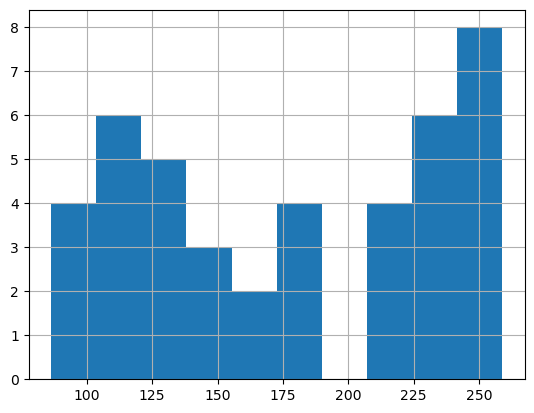

In [40]:
batch_1["RFU"].hist()

In [39]:
batch_1.groupby(
    ["Compound", "Concentration"]
)["RFU"].agg(["count", "mean", "std", "median"])

count        mean        std   median
Compound  Concentration                                       
CX-101    0.1                5  116.900000   6.511939  118.110
          1.0                7  137.160000   6.935481  133.810
          10.0               6  174.416667   3.873188  176.475
          100.0              6  217.693333  10.307763  215.405
          1000.0             6  237.900000   6.571341  239.595
CX101     1000.0             1  249.830000        NaN  249.830
Ionomycin 1000.0             5  251.232000   7.324416  251.280
Vehicle   0.0                6   97.316667   8.425705   97.425

In [23]:
batch_2.groupby(
    ["compound", "Conc"]
)["RFU"].agg(["count", "mean", "std", "median"])

count        mean        std   median
compound  Conc                                           
CX-101    0.001         1  113.750000        NaN  113.750
          0.100         5  111.434000   9.346707  107.730
          1.000         5  132.346000   4.222538  134.170
          10.000        6  162.225000   6.894295  162.405
          100.000       6  243.163333  86.699834  208.835
          1000.000      6  227.205000   4.665545  225.130
Ionomycin 1000.000      6  239.816667   7.963139  241.785
Vehicle   0.000         6   97.165000   3.432706   97.550
cx-101    0.100         1  105.970000        NaN  105.970

In [24]:
batch_3.groupby(
    ["Compound", "Concentration"]
)["RFU"].agg(["count", "mean", "std", "median"])

count        mean        std   median
Compound  Concentration                                       
 CX-101   1000.0000          1  266.650000        NaN  266.650
CX-101    0.0001             1  187.460000        NaN  187.460
          0.1000             6  116.528333   8.954870  113.610
          1.0000             6  136.561667   5.553901  136.505
          10.0000            5  174.322000   8.719545  174.550
          100.0000           6  224.783333   6.661137  223.465
          1000.0000          6  214.161667  88.063747  248.965
Ionomycin 1000.0000          5  252.530000   7.656151  255.770
Vehicle   0.0000             6  103.723333   4.758397  105.610

In [20]:
combined = pd.concat(
    [batch_1, batch_2, batch_3],
    ignore_index=True
)

not save to  combine them without prep

## condense initial observations into course of action


->>> notes